# 15 — Validate the stratified 2025 sample against native L2 fire pixels

This notebook verifies the 39 downloaded granules and compares every selected 2025 Cameroon FIRMS point with its same-source MODIS/VIIRS L2 active-fire pixel list and fire mask. It keeps cross-satellite candidate status, product collection/process lineage, confidence semantics, and FRP separate.

A successful source-pixel join establishes only that the sample FIRMS row is represented in that product granule. A cross-satellite candidate/no-candidate label is not fire identity or truth. This selected, balanced engineering sample does not estimate accuracy or support an anomaly model.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
ROOT=Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.firewatch.swath_validation import inspect_modis_granule, inspect_viirs_granule
SAMPLE=ROOT/'data/reference/validation_sample_2025.csv'
PLAN=ROOT/'data/reference/validation_granule_plan_2025.csv'
PLAN_META=ROOT/'data/reference/validation_sample_2025.metadata.json'
GRANULE_DIR=ROOT/'data/reference/granules/validation_2025'
DOWNLOAD_META=GRANULE_DIR/'download_manifest.json'
OUT=ROOT/'data/processed/source_pixel_validation_2025_stratified.csv'
sample=pd.read_csv(SAMPLE)
sample=sample.loc[sample.selection_status.eq('matched')].copy()
plan=pd.read_csv(PLAN)
plan_meta=json.loads(PLAN_META.read_text(encoding='utf-8'))
download_meta=json.loads(DOWNLOAD_META.read_text(encoding='utf-8'))
assert hashlib.sha256(PLAN.read_bytes()).hexdigest()==download_meta['plan_sha256']
assert len(sample)==39 and len(plan)==39 and download_meta['download_count']==39
print('Verified plan SHA-256:',download_meta['plan_sha256'])
print('Downloaded granules:',download_meta['download_count'],'| maximum allowed:',download_meta['max_total_mb'],'MB')

Verified plan SHA-256: 29046d9dc74a9ce14106f68b2992372aa070582d4c66f9b929627912e0f6ee08
Downloaded granules: 39 | maximum allowed: 100.0 MB


In [2]:
# Verify every transferred byte before decoding any science variables.
downloads={item['filename']:item for item in download_meta['downloads']}
assert set(downloads)=={Path(url).name for url in plan.data_url}
actual_bytes=0
for filename,item in downloads.items():
    path=GRANULE_DIR/filename
    assert path.is_file(), f'Missing granule: {filename}'
    size=path.stat().st_size
    digest=hashlib.sha256(path.read_bytes()).hexdigest()
    assert size==item['bytes'] and digest==item['sha256'], f'Integrity check failed: {filename}'
    actual_bytes+=size
print(f'All {len(downloads)} granules passed byte-count and SHA-256 checks.')
print(f'Actual transfer: {actual_bytes:,} bytes ({actual_bytes/1024**2:.3f} MiB; {actual_bytes/1e6:.3f} decimal MB).')

All 39 granules passed byte-count and SHA-256 checks.
Actual transfer: 72,722,137 bytes (69.353 MiB; 72.722 decimal MB).


In [3]:
# Match each CSV coordinate to the nearest active-fire pixel record, then inspect its mask value.
results=[]
for position,row in enumerate(sample.itertuples(index=False),1):
    path=GRANULE_DIR/Path(row.data_url).name
    record=downloads[path.name]
    kwargs={'observation_latitude':float(row.latitude),'observation_longitude':float(row.longitude)}
    if row.short_name in {'MOD14','MYD14'}:
        native=inspect_modis_granule(path,**kwargs)
    elif row.short_name in {'VNP14IMG','VJ114IMG','VJ214IMG'}:
        native=inspect_viirs_granule(path,**kwargs)
    else:
        raise ValueError(f'Unexpected product: {row.short_name}')
    stamp=pd.Timestamp(row.observation_time_utc)
    granule_start=pd.Timestamp(native['start_time'])
    granule_end=pd.Timestamp(native['end_time'])
    if granule_start.tzinfo is None: granule_start=granule_start.tz_localize('UTC')
    if granule_end.tzinfo is None: granule_end=granule_end.tz_localize('UTC')
    native.update({
        'observation_id':row.observation_id,'quarter':row.quarter,
        'satellite':row.satellite,'short_name':row.short_name,
        'candidate_status':bool(row.cross_platform_candidate),
        'candidate_status_label':'has_candidate_link' if row.cross_platform_candidate else 'no_candidate_link_under_1km_3h',
        'observation_time_utc':row.observation_time_utc,
        'csv_latitude':float(row.latitude),'csv_longitude':float(row.longitude),
        'observation_time_in_granule':bool(granule_start<=stamp<=granule_end),
        'candidate_frame_size':int(row.stratum_frame_size_cameroon),
        'producer_granule_id':row.producer_granule_id,
        'download_bytes':int(record['bytes']),'download_sha256':record['sha256'],
    })
    results.append(native)
    print(f"{position:02d}/39 {row.satellite:5s} {row.quarter} {'candidate' if row.cross_platform_candidate else 'unlinked':10s} nearest={native['distance_km']*1000:.2f} m mask={native['fire_mask_class']}",flush=True)
validation=pd.DataFrame(results)
assert len(validation)==39 and validation.observation_id.is_unique
assert validation.observation_time_in_granule.all()
assert validation.distance_km.max()<0.05, 'At least one sample row is more than 50 m from its nearest native fire-pixel record'
assert validation.fire_mask_class.isin([7,8,9]).all(), 'At least one nearest active-fire record does not resolve to a fire mask class'
print('\n39/39 source-pixel joins, granule-time checks, and fire-mask-class checks passed.')

01/39 Aqua  Q1 candidate  nearest=5.97 m mask=8


02/39 Aqua  Q1 unlinked   nearest=6.61 m mask=8


03/39 N20   Q1 candidate  nearest=0.29 m mask=7


04/39 N20   Q1 unlinked   nearest=0.45 m mask=8


05/39 N21   Q1 candidate  nearest=0.54 m mask=9


06/39 N21   Q1 unlinked   nearest=0.48 m mask=8


... (30 outputs left out)

37/39 SNPP  Q4 unlinked   nearest=0.60 m mask=8


38/39 Terra Q4 candidate  nearest=7.17 m mask=8


39/39 Terra Q4 unlinked   nearest=5.75 m mask=8



39/39 source-pixel joins, granule-time checks, and fire-mask-class checks passed.


In [4]:
# Product- and association-stratum summaries. Do not compare sensor-native confidence numerically.
summary=(validation.groupby(['short_name','candidate_status_label'],as_index=False)
         .agg(rows=('observation_id','count'),
              median_pixel_distance_m=('distance_km',lambda x:float(x.median()*1000)),
              maximum_pixel_distance_m=('distance_km',lambda x:float(x.max()*1000)),
              fire_mask_matches=('fire_mask_class',lambda x:int(x.isin([7,8,9]).sum()))))
display(summary)
display(validation[['quarter','satellite','short_name','collection_version','process_version','observation_time_in_granule','distance_km','fire_mask_class','candidate_status','confidence_code_or_percent','confidence_semantics','frp_mw']].sort_values(['quarter','satellite','candidate_status']))
print('Mask classes:',validation.fire_mask_class.value_counts().sort_index().to_dict())
print('Confidence remains native: MODIS FP_confidence is percent; VIIRS FP_confidence is categorical code.')
print('FRP is retained per product and is not assumed cross-calibrated.')

,short_name,candidate_status_label,rows,median_pixel_distance_m,maximum_pixel_distance_m,fire_mask_matches
0,MOD14,has_candidate_link,3,5.688170,7.173293,3
1,MOD14,no_candidate_link_under_1km_3h,4,5.412531,6.035749,4
2,MYD14,has_candidate_link,4,4.825456,5.967446,4
3,MYD14,no_candidate_link_under_1km_3h,4,2.921632,6.609408,4
4,VJ114IMG,has_candidate_link,4,0.445740,0.532112,4
5,VJ114IMG,no_candidate_link_under_1km_3h,4,0.441240,0.492624,4
6,VJ214IMG,has_candidate_link,4,0.330527,0.541078,4
7,VJ214IMG,no_candidate_link_under_1km_3h,4,0.416245,0.522197,4
8,VNP14IMG,has_candidate_link,4,0.528571,0.546681,4
9,VNP14IMG,no_candidate_link_under_1km_3h,4,0.408261,0.602149,4


,quarter,satellite,short_name,collection_version,process_version,observation_time_in_granule,distance_km,fire_mask_class,candidate_status,confidence_code_or_percent,confidence_semantics,frp_mw
1,Q1,Aqua,MYD14,61,6.2.3,True,0.006609,8,False,60,Percent (0–100); fire-mask class carries low/n...,10.989743
0,Q1,Aqua,MYD14,61,6.2.3,True,0.005967,8,True,65,Percent (0–100); fire-mask class carries low/n...,21.688564
3,Q1,N20,VJ114IMG,002,3.1.9,True,0.000448,8,False,8,"Categorical code: 7 low, 8 nominal, 9 high",5.715535
2,Q1,N20,VJ114IMG,002,3.1.9,True,0.000290,7,True,7,"Categorical code: 7 low, 8 nominal, 9 high",2.976328
5,Q1,N21,VJ214IMG,002,3.1.9,True,0.000484,8,False,8,"Categorical code: 7 low, 8 nominal, 9 high",2.516406
4,Q1,N21,VJ214IMG,002,3.1.9,True,0.000541,9,True,9,"Categorical code: 7 low, 8 nominal, 9 high",14.350101
7,Q1,SNPP,VNP14IMG,002,3.1.9,True,0.000347,8,False,8,"Categorical code: 7 low, 8 nominal, 9 high",0.943076
6,Q1,SNPP,VNP14IMG,002,3.1.9,True,0.000336,8,True,8,"Categorical code: 7 low, 8 nominal, 9 high",45.449654
9,Q1,Terra,MOD14,61,6.2.3,True,0.005077,8,False,33,Percent (0–100); fire-mask class carries low/n...,28.554094
8,Q1,Terra,MOD14,61,6.2.3,True,0.004233,8,True,66,Percent (0–100); fire-mask class carries low/n...,20.694895


Mask classes: {7: 4, 8: 31, 9: 4}
Confidence remains native: MODIS FP_confidence is percent; VIIRS FP_confidence is categorical code.
FRP is retained per product and is not assumed cross-calibrated.


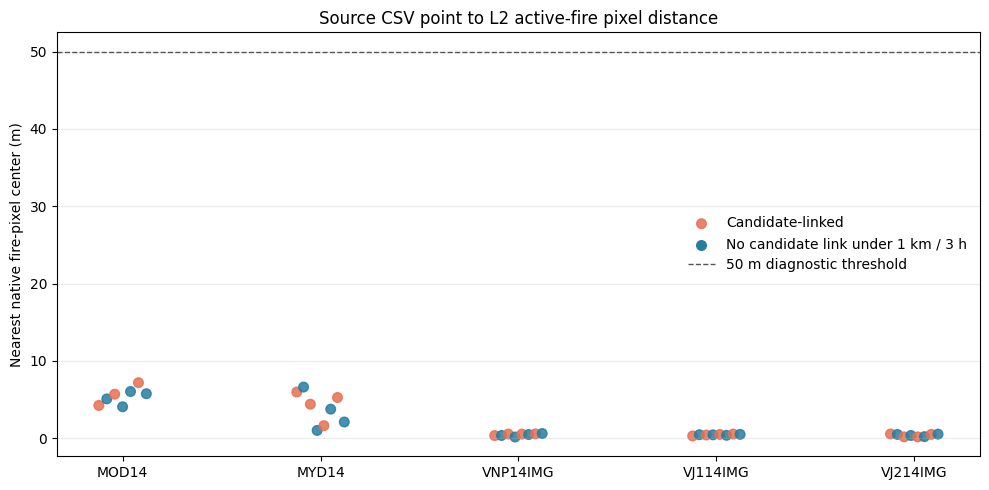

In [5]:
# Visualize coordinate-to-pixel residuals with a 50 m diagnostic threshold.
fig,ax=plt.subplots(figsize=(10,5))
order=['MOD14','MYD14','VNP14IMG','VJ114IMG','VJ214IMG']
for x,product in enumerate(order):
    group=validation.loc[validation.short_name.eq(product)]
    jitter=np.linspace(-.12,.12,len(group)) if len(group)>1 else [0]
    ax.scatter(x+jitter,group.distance_km.to_numpy()*1000,
               c=np.where(group.candidate_status,'#e76f51','#277da1'),s=48,alpha=.85,
               label='Candidate-linked' if x==0 else None)
    if x==0: ax.scatter([],[],c='#277da1',s=48,label='No candidate link under 1 km / 3 h')
ax.axhline(50,color='#555',linestyle='--',linewidth=1,label='50 m diagnostic threshold')
ax.set_xticks(range(len(order)),order); ax.set_ylabel('Nearest native fire-pixel center (m)')
ax.set_title('Source CSV point to L2 active-fire pixel distance')
ax.grid(axis='y',alpha=.25); ax.legend(frameon=False); fig.tight_layout(); plt.show()

In [6]:
# Save row-level evidence and a summary metadata sidecar.
validation.to_csv(OUT,index=False)
meta={
 'sample_plan_sha256':hashlib.sha256(PLAN.read_bytes()).hexdigest(),
 'download_manifest_sha256':hashlib.sha256(DOWNLOAD_META.read_bytes()).hexdigest(),
 'sample_rows_inspected':len(validation),
 'downloaded_granule_count':len(downloads),
 'actual_download_bytes':actual_bytes,
 'all_sha256_verified':True,
 'granule_time_matches':int(validation.observation_time_in_granule.sum()),
 'nearest_fire_pixel_rows_within_50m':int((validation.distance_km<0.05).sum()),
 'native_fire_mask_classes':validation.fire_mask_class.value_counts().sort_index().to_dict(),
 'candidate_status_counts':validation.candidate_status_label.value_counts().to_dict(),
 'interpretation':'Source-pixel linkage check for a stratified engineering sample; not event identity, independent ground truth, or a probability sample for accuracy metrics.',
 'limitations':['Sample was stratified by source, quarter, and candidate status.','Non-candidate means no 1 km / 3 h link in this archive, not no fire.','CMR catalog match is not independent pixel-valid coverage.','MODIS confidence percentages and VIIRS categorical confidence codes are not directly comparable.','FRP is sensor-native and not assumed cross-calibrated.']
}
OUT.with_suffix('.metadata.json').write_text(json.dumps(meta,indent=2),encoding='utf-8')
print('Saved:',OUT.relative_to(ROOT))
print(json.dumps({k:meta[k] for k in ['sample_rows_inspected','downloaded_granule_count','actual_download_bytes','granule_time_matches','nearest_fire_pixel_rows_within_50m','native_fire_mask_classes']},indent=2))

Saved: data\processed\source_pixel_validation_2025_stratified.csv
{
  "sample_rows_inspected": 39,
  "downloaded_granule_count": 39,
  "actual_download_bytes": 72722137,
  "granule_time_matches": 39,
  "nearest_fire_pixel_rows_within_50m": 39,
  "native_fire_mask_classes": {
    "7": 4,
    "8": 31,
    "9": 4
  }
}


## Interpretation

All 39 selected rows were found within their source granule intervals, and each CSV coordinate was within 50 m of a native active-fire pixel record whose fire mask reports class 7, 8, or 9. The nearest centers were much closer than 50 m for this sample. This confirms the source-level join and reader/indexing path for the products and sample tested. It does not validate whether a candidate link joins detections of the same fire: notably, observations with no link under the selected 1 km / 3 h envelope still map to their own native fire pixels. Preserve these as separate facts in the dashboard and any later model evaluation.